## Exploring High-Protein Food Trends using the NomsAPI and GridDB 

In [1]:
##Specify the path to your image file
image_path = 'franki-chamaki-ivfp_yxZuYQ-unsplash.jpg'

width = 550

## Display the image
#Image(filename=image_path, width=width)

from IPython.display import HTML, display

display(HTML(f"""
<div style="text-align:center;">
    <img src="{image_path}" width="{width}">,
    <p><i><center>Food and Nutrition Data (Photo by <a href="https://unsplash.com/@franki?utm_source=unsplash&utm_medium=referral&utm_content=creditCopyText">Franki Chamaki</a> on <a href="https://unsplash.com/photos/grocery-store-aisle-with-stocked-shelves-ivfp_yxZuYQ?utm_source=unsplash&utm_medium=referral&utm_content=creditCopyText">Unsplash</a>) </i></p>
</div>
"""))

## Introduction

<p> The growing focus on gut health and protein is hard to miss, especially when we walk into a grocery store or scroll through YouTube. While gut health and protein have long been recognized as important aspects of nutritional health, their importance has increased in recent years. From food labels to fitness videos, protein has become ubiquitous in health-related conversations. As a result, most brands have launched high-protein meal replacements, supplements, and even protein-enriched snacks and beverages. </p>

<p> With a cornucopia of protein-rich foods available in the market, it becomes increasingly important to look beyond the marketing claims and examine whether these products are truly as healthy as they claim to be. Moreover, protein content alone does not tell the whole nutritional story. When evaluating these products, factors such as calorie content, sodium, saturated fat, and other nutrients are equally worth examining. </p>

<p> In this article, we use the Noms API to retrieve nutritional information about high-protein foods and store the data in GridDB. We then leverage GridDB's SQL capabilities to explore protein density, compare sodium-to-protein and saturated-fat-to-protein ratios, and analyze nutrient information across food products and brands. Along the way, we use GridDB's powerful query engine and it's SQL features to uncover insights. </p>

## Pre-requisites

In [2]:
#File system and I/O operations
import os

# Data manipulation 
import pandas as pd
import numpy as np
from pathlib import Path
from dotenv import load_dotenv

#Time functions
import time
import math
from datetime import datetime, timedelta


#Debugging & Display
import http
import http.client
http.client.HTTPConnection.debuglevel = 0
from IPython.display import HTML, display
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import textwrap
import math


# Data Processing, Encoding and Serialization
import requests
import base64
import json

## Understanding the Noms Food and Nutrition API

<a href ="https://noms.sh/docs"> Noms </a> is a REST API offering a wide range of nutrition data on brands and their corresponding food products. The API provides detailed nutrient information at the product-grain level and assigns categories (food groups) to each product. The Noms API data model centers food as the primary entity. A food can belong to a Brand, be classified under a Food Group, and contain nutritional information represented through Nutrients. Below is a basic structure of the API entities.

In [122]:
##Specify the path to your image file
image_path = 'Img1_Noms_API_dataset.png'

width = 800
height = 200

## Display the image
#Image(filename=image_path, width=width)

display(HTML(f"""
<div style="text-align:center;">
    <img src="{image_path}" width="{width}" height="{height}">,
    <p><i><center>Figure 1: The Noms API - Data Model</i></p>
</div>
"""))

## Authenticating and Configuring the Noms API

To access the Noms API, we load the API key from an environment file using 'python-dotenv' and pass it through the X-API-Key request header. One is required to choose a food market to be able to retrieve data if the free tier of the Noms API is being used. For our demonstration, we configure US as the market using the /v1/market endpoint. Once configured, subsequent food queries are automatically restricted to the selected market.

In [3]:
os.chdir("Your Working Directory")
load_dotenv("NOMS_API_KEY.env")
API_KEY = os.getenv("NOMS_API_KEY")

In [4]:
if API_KEY:
    print("API key loaded successfully.")
else:
    print("API key not found.")

API key loaded successfully.


## Selecting a Food Market

In [5]:
# Filtering down to the US Market
conn = http.client.HTTPSConnection("api.noms.sh")

headers = {
    "X-API-Key": API_KEY,
    "Content-Type": "application/json"
}

payload = json.dumps({
    "market": "US"
})

conn.request(
    "PUT",
    "/v1/market",
    body=payload,
    headers=headers
)

response = conn.getresponse()

print("Status:", response.status)
print("Reason:", response.reason)

#body = response.read().decode()
#print(body)

conn.close()

Status: 200
Reason: OK


In [6]:
endpoint = (
    "/v1/foods"
    "?q=protein"
    "&page_size=20"
    "&include=brand%2Cnutrients%2Cfood_group"
    "&nutrient[PROTEIN][gte]=10"
    "&sort=-nutrient[PROTEIN]"
)

conn.request("GET", endpoint, headers=headers)

response = conn.getresponse()

print("Status:", response.status)
print("Reason:", response.reason)

print("RateLimit-Limit:", response.getheader("RateLimit-Limit"))
print("RateLimit-Remaining:", response.getheader("RateLimit-Remaining"))
print("RateLimit-Reset:", response.getheader("RateLimit-Reset"))
print("Retry-After:", response.getheader("Retry-After"))

data = json.loads(response.read().decode())

#body = response.read().decode()
#print("Response:", body)

conn.close()

#print(json.dumps(data, indent=2))

Status: 200
Reason: OK
RateLimit-Limit: 250
RateLimit-Remaining: 249
RateLimit-Reset: 41
Retry-After: None


## Fetching High Protein Foods - Fetching a Subset

In [7]:
def fetch_foods(url, headers, output_file="high_protein_foods.jsonl"):
    total = 0

    with open(output_file, "a", encoding="utf-8") as f:
        while url:
            response = requests.get(url, headers=headers)

            if response.status_code == 429:
                retry_after = int(response.headers.get("Retry-After", 60))
                print(f"Rate limit reached. Waiting {retry_after} seconds...")
                time.sleep(retry_after)
                continue

            if response.status_code == 403:
                error = response.json()

                if error.get("type") == "/problems/result-depth-exceeded":
                    print(
                        f"Result depth limit reached at "
                        f"{error.get('cap', 1000)} records."
                    )
                    break

                response.raise_for_status()

            response.raise_for_status()

            result = response.json()
            foods = result["data"]

            for food in foods:
                f.write(json.dumps(food) + "\n")

            f.flush()

            total += len(foods)
            #print(f"Saved {total} foods")

            url = result["links"].get("next")

            if url:
                time.sleep(1)

    return total

In [8]:
url = (
    "https://api.noms.sh/v1/foods"
    "?q=protein"
    "&page_size=20"
    "&include=brand%2Cnutrients%2Cfood_group"
    "&nutrient[PROTEIN][gte]=10"
    "&sort=-nutrient[PROTEIN]"
)

headers = {
    "X-API-Key": API_KEY
}


fetch_foods(
    url,
    headers,
    output_file="high_protein_foods.jsonl"
)

Result depth limit reached at 1000 records.


1000

In [9]:
food_data = pd.read_json(
    "high_protein_foods.jsonl",
    lines=True
)

food_data = (
    food_data
    .drop_duplicates(subset="id")
    .reset_index(drop=True)
)

print("Total food rows:", len(food_data))
print("Unique foods:", food_data["id"].nunique())

Total food rows: 1000
Unique foods: 1000


## Transforming the Norms Dataset

The Noms API returns each food record as a nested JSON object. We store these records as JSONL and subsequently load them into a Pandas DataFrame. However, nested attributes such as brand and food_group are stored as such, while nutrients contain an array of nutrient objects. While this structure is convenient for transferring data through a REST API, it does not lend itself well enough for analysis. Hence, we use Pandas as the transformation layer between Rest API and GridDB to convert the nested nutrient measurements into individual records that can be queried using SQL. We create separate datasets for foods, brands, food groups, and food-nutrient measurements, which can later be combined during analysis using their respective identifiers.

In [10]:
foods_df = food_data[
    [
        "id", "barcode", "name", "description",
        "country_of_origin", "ingredients_text",
        "is_foundational", "basis_unit",
        "brand_id", "food_group_id"
    ]
].copy()

foods_df = foods_df.rename(columns={"id": "food_id"})

In [11]:
brand_details = pd.json_normalize(
    food_data["brand"].dropna()
)

brands_df = (
    brand_details[["id", "name"]]
    .rename(columns={
        "id": "brand_id",
        "name": "brand_name"
    })
    .drop_duplicates(subset="brand_id")
    .reset_index(drop=True)
)

brands_df.head()

,brand_id,brand_name
0,ClplFHnRuEWN,Shop Santé
1,1XbF9vxQWjN2,Nutricost
2,Bhh1zm98PrvS,Zammex Nutrition
3,Cf25LAtjMrLe,Paleovalley
4,GrMwynMtWIGY,Canadian Protein


In [12]:
food_group_details = pd.json_normalize(
    food_data["food_group"].dropna()
)

food_groups_df = (
    food_group_details[["id", "name"]]
    .rename(columns={
        "id": "food_group_id",
        "name": "food_group_name"
    })
    .drop_duplicates(subset="food_group_id")
    .reset_index(drop=True)
)

food_groups_df.head()

,food_group_id,food_group_name
0,SWEETS,Sweets
1,BEVERAGES_NONALCOHOLIC,Non-Alcoholic Beverages
2,DAIRY,Dairy
3,SUPPLEMENTS,Supplements
4,GRAINS,Grains


In [13]:
nutrients_df = food_data[["id", "nutrients"]].explode("nutrients")
nutrients_df.head()

,id,nutrients
0,7cWyiWtpRHBM,"{'id': 'ENERGY', 'name': 'Energy', 'value': '2..."
0,7cWyiWtpRHBM,"{'id': 'PROTEIN', 'name': 'Protein', 'value': ..."
0,7cWyiWtpRHBM,"{'id': 'CARBOHYDRATE', 'name': 'Carbohydrate, ..."
1,Bczc8BJ9HK4B,"{'id': 'PROTEIN', 'name': 'Protein', 'value': ..."
2,c6DQx2EgxHNe,"{'id': 'ENERGY', 'name': 'Energy', 'value': '4..."


In [14]:
nutrient_details = pd.json_normalize(nutrients_df["nutrients"])

food_nutrients_df = pd.concat(
    [
        nutrients_df["id"].reset_index(drop=True).rename("food_id"),
        nutrient_details
    ],
    axis=1
)

food_nutrients_df.head()

,food_id,id,name,value,unit
0,7cWyiWtpRHBM,ENERGY,Energy,275.0,kcal
1,7cWyiWtpRHBM,PROTEIN,Protein,100.0,g
2,7cWyiWtpRHBM,CARBOHYDRATE,"Carbohydrate, by difference",0.000798,g
3,Bczc8BJ9HK4B,PROTEIN,Protein,100.0,g
4,c6DQx2EgxHNe,ENERGY,Energy,400.0,kcal


In [15]:
print("Foods:", food_data["id"].nunique())
print("Brands:", brands_df["brand_id"].nunique())
print("Food groups:", food_groups_df["food_group_id"].nunique())
print("Unique nutrients:", food_nutrients_df["id"].nunique())
print("Food-nutrient records:", len(food_nutrients_df))

Foods: 1000
Brands: 432
Food groups: 5
Unique nutrients: 58
Food-nutrient records: 10239


## Utility Functions to Create a Container Structure

Below are some utility functions to determine data types from the Pandas DataFrame and then convert them to GridDB equivalent data types. The function generate_griddb_data_obj() calls the function map_dtype_to_griddb() to create the base container structure with the column-level datatypes.

In [16]:
def map_dtype_to_griddb(dtype):
    """
    Maps Pandas data types to GridDB data types.
    """
    if pd.api.types.is_integer_dtype(dtype):
        return "INTEGER"
    elif pd.api.types.is_float_dtype(dtype):
        return "DOUBLE"
    elif pd.api.types.is_bool_dtype(dtype):
        return "BOOL"
    ##elif pd.api.types.is_datetime64_any_dtype(dtype):
        ##return "LONG"  # GridDB stores timestamps as LONG
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return "TIMESTAMP"
    else:
        return "STRING"

In [17]:
def generate_griddb_data_obj(
    df,
    container_name="MyContainer",
    container_type="COLLECTION",
    rowkey=False,
    dtype_overrides={
        "barcode": "STRING",
        "description": "STRING",
        "scientific_name": "STRING"
    }):
    """ 
    Generates a GridDB container schema from a Pandas DataFrame.     
    Generates a GridDB container data object for API request.

    - Uses explicit type overrides when provided.
    - Identifies nested JSON values.
    - Defaults empty columns to STRING.
    """

    dtype_overrides = dtype_overrides or {}
    columns = []

    for col in df.columns:
        series = df[col]

        # Explicitly specified datatype
        if col in dtype_overrides:
            griddb_type = dtype_overrides[col]

        # Column contains no non-null values
        elif series.isna().all():
            griddb_type = "STRING"

        # Check for dictionaries and lists
        elif series.dtype == "object" and series.map(
            lambda x: isinstance(x, (dict, list))
        ).any():
            griddb_type = "STRING"

        # Standard Pandas datatype mapping
        else:
            griddb_type = map_dtype_to_griddb(series.dtype)

        columns.append({
            "name": col,
            "type": griddb_type
        })

    return {
        "container_name": container_name,
        "container_type": container_type,
        "rowkey": rowkey,
        "columns": columns
    }

## Container Creation in GridDB 

For this demonstration, we create four GridDB containers to store brand information, individual food products, their respective food groups (categories), and detailed nutritional information. GridDB supports two types of containers based on the nature of the data being stored. Time-series containers are useful for time-sensitive applications that involve sensor readings for real-time monitoring or IoT use cases. Collections are used to store lookup data, transactional data and analytical data.

In [18]:
username = "XXXX" # Provide your GridDB credentials here 
password =   "XXXX"
credentials = f"{username}:{password}"
encoded_credentials = base64.b64encode(credentials.encode()).decode()
#print(f"Encoded credentials: Basic {encoded_credentials}")

In [17]:
#Construct an object to hold the request headers (ensure that you replace the XXX placeholder with the correct value that matches the credentials for your GridDB instance)
#header_obj = {"Authorization":"Basic {EncodedAuthorizationToken}","Content-Type":"application/json; charset=UTF-8","User-Agent":"PostmanRuntime/7.29.0"}

header_obj = {
    "Authorization": f"Basic {encoded_credentials}",  # Add encoded credentials here
    "Content-Type": "application/json",  # Optional; depends on API requirements
    "charset": "UTF-8",
    "User-Agent":"PostmanRuntime/7.29.0"
}

#Construct the base URL based on your GridDB cluster you'd like to connect to (ensure that you replace the placeholders in the URL below with the correct values that correspond to your GridDB instance)
base_url = 'https://[host]:[port]/griddb/v2/[clustername]/dbs/[database_name]/'

In [18]:
data_obj = generate_griddb_data_obj(foods_df, container_name="food_info",container_type = "COLLECTION", rowkey=False)

#Set up the GridDB WebAPI URL
url = base_url + 'containers'

#Invoke the GridDB WebAPI with the headers and the request body
x = requests.post(url, json = data_obj, headers = header_obj)
x.text

'{"version":"v2","errorCode":0,"errorMessage":"Container already existed"}'

In [38]:
data_obj = generate_griddb_data_obj(brands_df, container_name="brands_df",container_type = "COLLECTION", rowkey=False)

#Set up the GridDB WebAPI URL
url = base_url + 'containers'

#Invoke the GridDB WebAPI with the headers and the request body
x = requests.post(url, json = data_obj, headers = header_obj)
x.text

''

In [129]:
data_obj = generate_griddb_data_obj(food_groups_df, container_name="food_groups_df",container_type = "COLLECTION", rowkey=False)

#Set up the GridDB WebAPI URL
url = base_url + 'containers'

#Invoke the GridDB WebAPI with the headers and the request body
x = requests.post(url, json = data_obj, headers = header_obj)
x.text

'{"version":"v2","errorCode":0,"errorMessage":"Container already existed"}'

In [140]:
data_obj = generate_griddb_data_obj(food_nutrients_df, container_name="food_nutrients_df",container_type = "COLLECTION", rowkey=False)

#Set up the GridDB WebAPI URL
url = base_url + 'containers'

#Invoke the GridDB WebAPI with the headers and the request body
x = requests.post(url, json = data_obj, headers = header_obj)
x.text

''

## Data Ingestion in GridDB

#### Utility Function to Ingest Rows

The function below helps with ingesting rows into the container in batches specified by the user.

In [19]:
def ingest_griddb_rows(df, url, header_obj, batch_size=1000):
    """
    Inserts Pandas DataFrame rows into a GridDB container
    using the GridDB Web API.
    """

    total_rows = len(df)
    total_batches = math.ceil(total_rows / batch_size)

    print(
        f"Starting ingestion of {total_rows:,} rows "
        f"in {total_batches} batches of {batch_size} each..."
    )

    start_time = time.time()
    inserted_rows = 0

    for i in range(total_batches):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, total_rows)

        batch_df = df.iloc[start_idx:end_idx]
        batch_json = batch_df.to_json(orient="values")

        try:
            response = requests.put(
                url,
                headers=header_obj,
                data=batch_json
            )

            elapsed = time.time() - start_time

            if response.status_code in [200, 201, 204]:
                inserted_rows += len(batch_df)

                print(
                    f"Batch {i+1}/{total_batches} | "
                    f"Rows {start_idx}-{end_idx-1} | "
                    f"Elapsed: {elapsed:.1f}s"
                )
            else:
                print(
                    f"Batch {i+1}/{total_batches} FAILED "
                    f"(HTTP {response.status_code}) - {response.text[:300]}"
                )
                break

        except requests.RequestException as e:
            print(f"Batch {i+1}/{total_batches} ERROR: {e}")
            break

    print(
        f"\nIngestion finished in "
        f"{time.time() - start_time:.1f} seconds."
    )
    print(f"Rows successfully submitted: {inserted_rows:,}/{total_rows:,}")

    return inserted_rows

### Loading Data into the container 'food_info'

In [ ]:
#Setup the URL to be used to invoke the GridDB WebAPI to register rows in the container created previously
url = base_url + 'containers/food_info/rows'
print(url)

In [27]:
ingest_griddb_rows(
    df=foods_df,
    url=url,
    header_obj=header_obj,
    batch_size=1000
)

Starting ingestion of 1,000 rows in 1 batches of 1000 each...
Batch 1/1 | Rows 0-999 | Elapsed: 2.4s

Ingestion finished in 2.4 seconds.
Rows successfully submitted: 1,000/1,000


1000

### Loading Data into the container 'brands_df'

In [ ]:
#Setup the URL to be used to invoke the GridDB WebAPI to register rows in the container created previously
url = base_url + 'containers/brands_df/rows'
print(url)

In [126]:
ingest_griddb_rows(
    df=brands_df,
    url=url,
    header_obj=header_obj,
    batch_size=1000
)

Starting ingestion of 432 rows in 1 batches of 1000 each...
Batch 1/1 | Rows 0-431 | Elapsed: 1.1s

Ingestion finished in 1.1 seconds.
Rows successfully submitted: 432/432


432

In [ ]:
#Setup the URL to be used to invoke the GridDB WebAPI to register rows in the container created previously
url = base_url + 'containers/food_groups_df/rows'
print(url)

In [128]:
ingest_griddb_rows(
    df=food_groups_df,
    url=url,
    header_obj=header_obj,
    batch_size=1000
)

Starting ingestion of 5 rows in 1 batches of 1000 each...
Batch 1/1 | Rows 0-4 | Elapsed: 1.1s

Ingestion finished in 1.1 seconds.
Rows successfully submitted: 5/5


5

In [ ]:
#Setup the URL to be used to invoke the GridDB WebAPI to register rows in the container created previously
url = base_url + 'containers/food_nutrients_df/rows'
print(url)

In [143]:
ingest_griddb_rows(
    df=food_nutrients_df,
    url=url,
    header_obj=header_obj,
    batch_size=1000
)

Starting ingestion of 10,239 rows in 11 batches of 1000 each...
Batch 1/11 | Rows 0-999 | Elapsed: 1.7s
Batch 2/11 | Rows 1000-1999 | Elapsed: 3.3s
Batch 3/11 | Rows 2000-2999 | Elapsed: 4.9s
Batch 4/11 | Rows 3000-3999 | Elapsed: 6.5s
Batch 5/11 | Rows 4000-4999 | Elapsed: 8.1s
Batch 6/11 | Rows 5000-5999 | Elapsed: 9.7s
Batch 7/11 | Rows 6000-6999 | Elapsed: 11.2s
Batch 8/11 | Rows 7000-7999 | Elapsed: 12.9s
Batch 9/11 | Rows 8000-8999 | Elapsed: 14.4s
Batch 10/11 | Rows 9000-9999 | Elapsed: 16.0s
Batch 11/11 | Rows 10000-10238 | Elapsed: 17.1s

Ingestion finished in 17.1 seconds.
Rows successfully submitted: 10,239/10,239


10239

## Utility Function to Create Visualizations

We create a function to create tables given a dataframe and the corresponding columns to be displayed.

In [113]:
def create_plotly_table(
    df,
    columns,
    column_labels,
    title,
    column_widths=None,
    row_height=35,
    header_height=40,
    width=1200
):
    """
    Creates a Plotly table with navy and white styling.
    """

    # Select columns
    table_df = df[columns].copy()

    # Calculate figure height
    fig_height = (
        len(table_df) * row_height
        + header_height
        + 100
    )

    fig = go.Figure(
        data=[
            go.Table(
                columnwidth=column_widths,

                header=dict(
                    values=column_labels,
                    align="center",
                    fill_color="#001F3F",
                    font=dict(size=13, color="white"),
                    height=header_height
                ),

                cells=dict(
                    values=[
                        table_df[col].tolist()
                        for col in table_df.columns
                    ],
                    align="center",
                    fill_color="#FFFFFF",
                    font=dict(size=12, color="#001F3F"),
                    height=row_height
                )
            )
        ]
    )

    fig.update_layout(
        title=title,
        title_x=0.5,
        width=width,
        height=fig_height,
        margin=dict(l=10, r=10, t=60, b=10)
    )

    return fig

## Querying the GridDB Database 

GridDB supports several options for creating containers and querying data. These include the JayDeBeAPI, Web API, GridDB CLI, and Python and Java Clients. In addition to this, the GridDB Cloud instance provides a web-based Management Console (GUI) that allows users to perform CRUD operations on containers (data tables) and execute SQL queries directly through the browser.

### Which foods deliver the most protein per calorie? (A look at the Protein Density)

Instead of ranking foods solely by protein, we could use protein density, as it offers a more nuanced perspective than absolute protein. A food with 40g of protein and 200kcal may have a higher protein density than one with 45g of protein and 450kcal. Protein Density is the ratio of protein to the underlying food's energy content. We retrieve food names from the food_info container. We then fetch the protein and energy records from the food_nutrients_df for the corresponding food name. Note that we exclude zero-calorie records to avoid division by zero. We retain foods containing at least 10g of protein, and return the 20 foods with the highest protein density. GridDB supports SQL joins, including self-joins that let us combine related records from the same table, which is useful in our example where we retrieve protein and energy records from the same table. Refer to this <a href = "https://docs.griddb.net/sqlreference/sql-commands-supported.html#join"> GridDB resource </a> to learn more about the JOIN capabilities in GridDB.

In [165]:
# id in the food_nutrients_df table is the nutrient_id
sql_query1 = (f"""SELECT
                    f.name AS food_name,
                    CAST(p.value AS DOUBLE) AS protein_g,
                    CAST(e.value AS DOUBLE) AS calories,
                    ROUND(
                        (CAST(p.value AS DOUBLE) * 100.0)
                        / CAST(e.value AS DOUBLE),
                        2
                    ) AS protein_per_100_kcal
                FROM food_info f
                INNER JOIN food_nutrients_df p
                    ON f.food_id = p.food_id
                    AND p.id = 'PROTEIN'
                INNER JOIN food_nutrients_df e
                    ON f.food_id = e.food_id
                    AND e.id = 'ENERGY'
                WHERE CAST(e.value AS DOUBLE) > 0
                  AND CAST(p.value AS DOUBLE) >= 10
                ORDER BY protein_per_100_kcal DESC
                LIMIT 20;
                """)

In [166]:
#Setup the URL to be used to invoke the GridDB WebAPI
url = base_url + 'sql'

# Construct the request body
request_body = json.dumps([
    {
        "type": "sql-select",
        "stmt": sql_query1
    }
])

# Disable HTTP debugging
http.client.HTTPConnection.debuglevel = 0

#Invoke the GridDB WebAPI
data_req1 = requests.post(url, data=request_body, headers=header_obj)

#Process the response received and construct a Pandas dataframe with the data from the response
myJson = data_req1.json()
foods_protein_density = pd.DataFrame(myJson[0]["results"], columns=[myJson[0]["columns"][0]["name"], myJson[0]["columns"][1]["name"],myJson[0]["columns"][2]["name"], myJson[0]["columns"][3]["name"]])

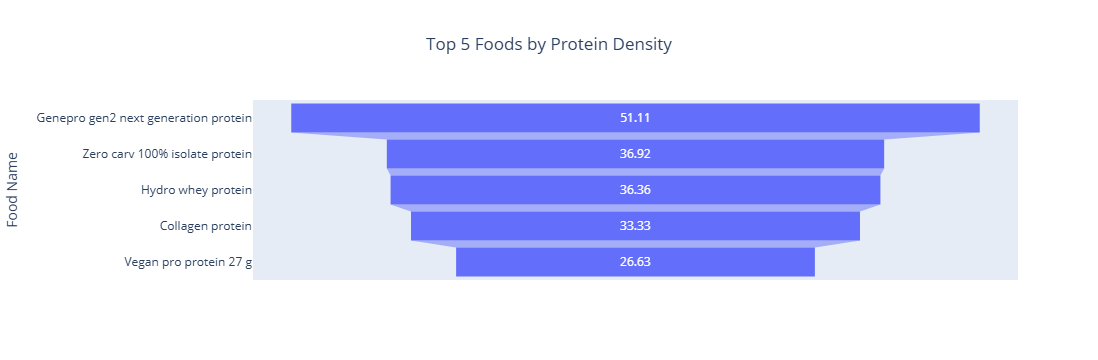

In [174]:
top_5_foods = foods_protein_density.nlargest(5, "protein_per_100_kcal")
fig = px.funnel(
    top_5_foods,
    x='protein_per_100_kcal',
    y='food_name',
    labels={
        'protein_per_100_kcal': 'Protein Density (g per 100 kcal)',
        'food_name': 'Food Name'
    },
    title='Top 5 Foods by Protein Density'
)

fig.update_layout(title_x=0.5)

fig.show()

### Which foods are simultaneously high in protein and low in sodium?

Our objective with this particular query is to identify foods with the highest and lowest sodium-to-protein ratios. The primary challenge is that both protein and sodium measurements are stored as separate records in the food_nutrients_df container rather than as individual columns. To tackle this, we join the container to itself (Self Join) on the food_id using two aliases, one for the protein measurements and the other for the sodium measurements.

Since the nutrient values are stored as strings, we use CAST() to convert them to numeric values before calculating the sodium-to-protein ratio. We then use a Cross Join to generate a cartesian product by combining every row from the 'foods' records with every row in the temporary table 'groups'. The intention here is to create two instances of each food record in the intermediate query result, one for each category. 
We then use ROW_NUMBER() with PARTITION BY and conditional sorting to rank foods separately by their highest and lowest ratios, selecting only the top 3 in each.

In [52]:
sql_query2 = (f"""SELECT
                    ranked.category,
                    ranked.food_name,
                    ranked.protein_g,
                    ranked.sodium_mg,
                    ROUND(ranked.sodium_per_protein_g, 4)
                        AS sodium_per_protein_g
                FROM (
                    SELECT
                        groups.category,
                        foods.food_name,
                        foods.protein_g,
                        foods.sodium_mg,
                        foods.sodium_per_protein_g,
                        ROW_NUMBER() OVER (
                            PARTITION BY groups.category
                            ORDER BY
                                CASE
                                    WHEN groups.category = 'Lowest 5'
                                    THEN foods.sodium_per_protein_g
                                    ELSE -foods.sodium_per_protein_g
                                END ASC,
                                foods.food_id
                        ) AS rank_position
                    FROM (
                        SELECT
                            f.food_id,
                            f.name AS food_name,
                            CAST(p.value AS DOUBLE) AS protein_g,
                            CAST(s.value AS DOUBLE) AS sodium_mg,
                            CAST(s.value AS DOUBLE) /
                                CAST(p.value AS DOUBLE)
                                AS sodium_per_protein_g
                        FROM food_info f
                        INNER JOIN food_nutrients_df p
                            ON f.food_id = p.food_id
                            AND p.id = 'PROTEIN'
                        INNER JOIN food_nutrients_df s
                            ON f.food_id = s.food_id
                            AND s.id = 'SODIUM'
                        WHERE CAST(p.value AS DOUBLE) >= 20
                          AND CAST(s.value AS DOUBLE) >= 0
                    ) foods
                    CROSS JOIN (
                        SELECT 'Lowest 5' AS category
                        UNION ALL
                        SELECT 'Highest 5' AS category
                    ) groups
                ) ranked
                WHERE ranked.rank_position <= 3
                ORDER BY ranked.category, ranked.rank_position;""")

In [53]:
#Setup the URL to be used to invoke the GridDB WebAPI
url = base_url + 'sql'

# Construct the request body
request_body = json.dumps([
    {
        "type": "sql-select",
        "stmt": sql_query2
    }
])

# Disable HTTP debugging
http.client.HTTPConnection.debuglevel = 0

#Invoke the GridDB WebAPI
data_req2 = requests.post(url, data=request_body, headers=header_obj)

#Process the response received and construct a Pandas dataframe with the data from the response
myJson = data_req2.json()
Sodium_to_protein_ratio = pd.DataFrame(myJson[0]["results"], columns=[myJson[0]["columns"][0]["name"], myJson[0]["columns"][1]["name"],myJson[0]["columns"][2]["name"], myJson[0]["columns"][3]["name"], myJson[0]["columns"][3]["name"]])

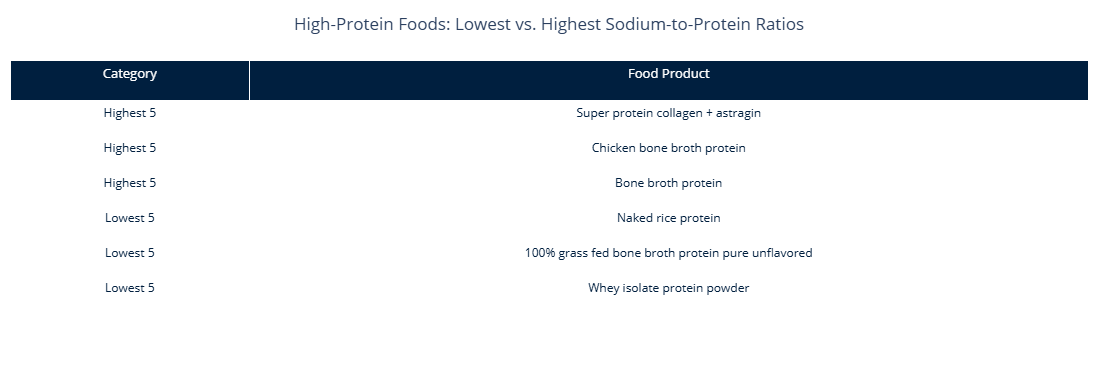

In [114]:
fig = create_plotly_table(
    df=Sodium_to_protein_ratio,
    columns=["category", "food_name"],
    column_labels=["Category", "Food Product"],
    title="High-Protein Foods: Lowest vs. Highest Sodium-to-Protein Ratios",
    column_widths=[100, 350]
)

fig.show()

### Which high-protein foods contain the least saturated fat?

In this query, we calculate the ratio of protein and saturated fat while ensuring that only foods having a finite sodium value are selected. We use subqueries and joins to achieve this. As the 'value' column is stored as a string datatype in the 'food_info' container, we use the CAST function to convert it into a DOUBLE datatype to perform calculations.

In [56]:
sql_query3 = (f"""SELECT
                    f.name AS food_name,
                    CAST(p.value AS DOUBLE) AS protein_g,
                    CAST(sf.value AS DOUBLE) AS saturated_fat_g,
                    ROUND(
                        CAST(sf.value AS DOUBLE) /
                        CAST(p.value AS DOUBLE),
                        4
                    ) AS saturated_fat_per_protein_g
                 FROM food_info f
                 INNER JOIN food_nutrients_df p
                    ON f.food_id = p.food_id
                    AND p.id = 'PROTEIN'
                 INNER JOIN food_nutrients_df sf
                    ON f.food_id = sf.food_id
                    AND sf.id = 'SATURATED_FAT'
                  WHERE CAST(p.value AS DOUBLE) >= 20
                  AND CAST(sf.value AS DOUBLE) >= 0
                  ORDER BY saturated_fat_per_protein_g ASC
                  LIMIT 10;""")

In [58]:
#Setup the URL to be used to invoke the GridDB WebAPI
url = base_url + 'sql'

# Construct the request body
request_body = json.dumps([
    {
        "type": "sql-select",
        "stmt": sql_query3
    }
])

# Disable HTTP debugging
http.client.HTTPConnection.debuglevel = 0

#Invoke the GridDB WebAPI
data_req3 = requests.post(url, data=request_body, headers=header_obj)

#Process the response received and construct a Pandas dataframe with the data from the response
myJson = data_req3.json()
High_protein_low_fat = pd.DataFrame(myJson[0]["results"], columns=[myJson[0]["columns"][0]["name"], myJson[0]["columns"][1]["name"],myJson[0]["columns"][2]["name"], myJson[0]["columns"][3]["name"]])

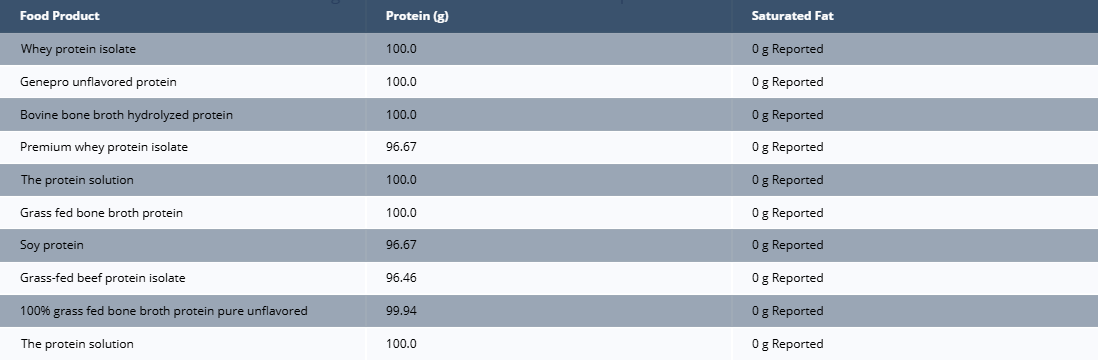

In [62]:
high_protein_low_fat_df = High_protein_low_fat.head(10).copy()

high_protein_low_fat_df["protein_g"] = high_protein_low_fat_df["protein_g"].round(2)

high_protein_low_fat_df["saturated_fat_g"] = high_protein_low_fat_df["saturated_fat_g"].apply(
    lambda x: "0 g Reported" if x == 0 else f"{x:.2f} g"
)

# Select and rename columns
high_protein_low_fat_df = high_protein_low_fat_df[["food_name", "protein_g", "saturated_fat_g"]]

high_protein_low_fat_df.columns = [
    "Food Product",
    "Protein (g)",
    "Saturated Fat"
]

fig = ff.create_table(
    high_protein_low_fat_df,
    colorscale=["#001F3F", "#FFFFFF"],
    height_constant=35
)

fig.update_layout(
    title="High-Protein Foods with the Lowest Reported Saturated Fat",
    title_x=0.5,
    height=500
)

fig.show()

### Which brands offer the highest average protein content?

GridDB supports standard aggregation functions such as AVG(), MAX()/MIN(), and COUNT(). We group the food products by brand and calculate the average, minimum, and maximum protein content within each group. The HAVING clause filters the results to include only brands with at least three distinct food products.

In [118]:
sql_query4 = (f"""SELECT
                  b.brand_name,
                  COUNT(DISTINCT f.food_id) AS product_count,
                   ROUND(AVG(CAST(n.value AS DOUBLE)), 2) AS avg_protein_g,
                   ROUND(MIN(CAST(n.value AS DOUBLE)), 2) AS min_protein_g,
                   ROUND(MAX(CAST(n.value AS DOUBLE)), 2) AS max_protein_g
                   FROM food_info f
                   INNER JOIN brands_df b
                   ON f.brand_id = b.brand_id
                   INNER JOIN food_nutrients_df n
                   ON f.food_id = n.food_id
                   AND n.id = 'PROTEIN'
                   GROUP BY b.brand_id, b.brand_name
                   HAVING COUNT(DISTINCT f.food_id) >= 3
                   ORDER BY avg_protein_g DESC
                   LIMIT 10;""")

In [119]:
#Setup the URL to be used to invoke the GridDB WebAPI to retrieve data from the container
url = base_url + 'sql'

# Construct the request body
request_body = json.dumps([
    {
        "type": "sql-select",
        "stmt": sql_query4
    }
])

# Disable HTTP debugging
http.client.HTTPConnection.debuglevel = 0

#Invoke the GridDB WebAPI
data_req4 = requests.post(url, data=request_body, headers=header_obj)

#Process the response received and construct a Pandas dataframe with the data from the response
myJson = data_req4.json()
Avg_protein = pd.DataFrame(myJson[0]["results"], columns=[myJson[0]["columns"][0]["name"], myJson[0]["columns"][1]["name"],myJson[0]["columns"][2]["name"], myJson[0]["columns"][3]["name"], myJson[0]["columns"][4]["name"]])

In [120]:
Avg_protein["avg_protein_g"] = Avg_protein["avg_protein_g"].round(2)
Avg_protein["min_protein_g"] = Avg_protein["min_protein_g"].round(2)
Avg_protein["max_protein_g"] = Avg_protein["max_protein_g"].round(2)

# Select and rename columns
Avg_protein = Avg_protein[
    [
        "brand_name",
        "product_count",
        "avg_protein_g",
        "min_protein_g",
        "max_protein_g"
    ]
]

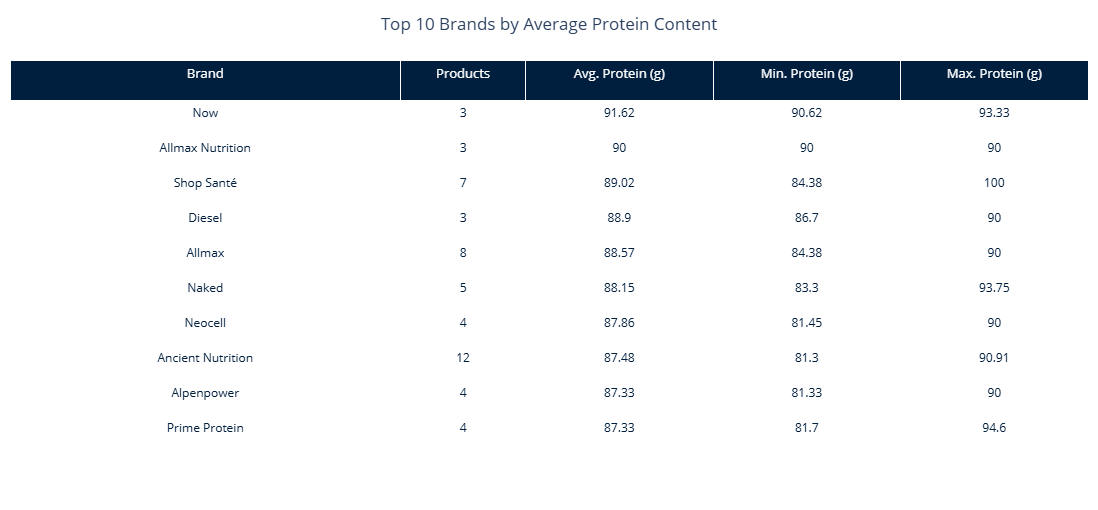

In [121]:
fig = create_plotly_table(
    df=Avg_protein,
    columns=[
        "brand_name",
        "product_count",
        "avg_protein_g",
        "min_protein_g",
        "max_protein_g"
    ],
    column_labels=[
        "Brand",
        "Products",
        "Avg. Protein (g)",
        "Min. Protein (g)",
        "Max. Protein (g)"
    ],
    title="Top 10 Brands by Average Protein Content",
    column_widths=[250, 80, 120, 120, 120]
)

fig.show()

### Which High-Protein Foods Have the Most Comprehensive Nutrient Records?

The objective here is to identify the top 10 foods with the most distinct nutrients listed in the brand. We also aim to display the detailed list of reported nutrients. We use COUNT(DISTINCT) to calculate the number of distinct (unique) nutrients reported for each food. We then use the GROUP_CONCAT() function to combine all nutrients into a single comma-separated string. This is similar to the STRING_AGG() function in PostgreSQL.

In [94]:
sql_query5 = (f"""SELECT
                f.name AS food_name,
                CAST(p.value AS DOUBLE) AS protein_g,
                COUNT(DISTINCT n.id) AS nutrient_count,
                GROUP_CONCAT(DISTINCT n.name, ', ') AS reported_nutrients
            FROM food_info f
            INNER JOIN food_nutrients_df p
                ON f.food_id = p.food_id
                AND p.id = 'PROTEIN'
            INNER JOIN food_nutrients_df n
                ON f.food_id = n.food_id
            WHERE CAST(p.value AS DOUBLE) >= 20
            GROUP BY
                f.food_id,
                f.name,
                p.value
            ORDER BY nutrient_count DESC
            LIMIT 10;""")

In [96]:
#Setup the URL to be used to invoke the GridDB WebAPI
url = base_url + 'sql'

# Construct the request body
request_body = json.dumps([
    {
        "type": "sql-select",
        "stmt": sql_query5
    }
])

# Disable HTTP debugging
http.client.HTTPConnection.debuglevel = 0

#Invoke the GridDB WebAPI
data_req5 = requests.post(url, data=request_body, headers=header_obj)

#Process the response received and construct a Pandas dataframe with the data from the response
myJson = data_req5.json()
protein_reported_nutrients = pd.DataFrame(myJson[0]["results"], columns=[myJson[0]["columns"][0]["name"], myJson[0]["columns"][1]["name"],myJson[0]["columns"][2]["name"], myJson[0]["columns"][3]["name"]])

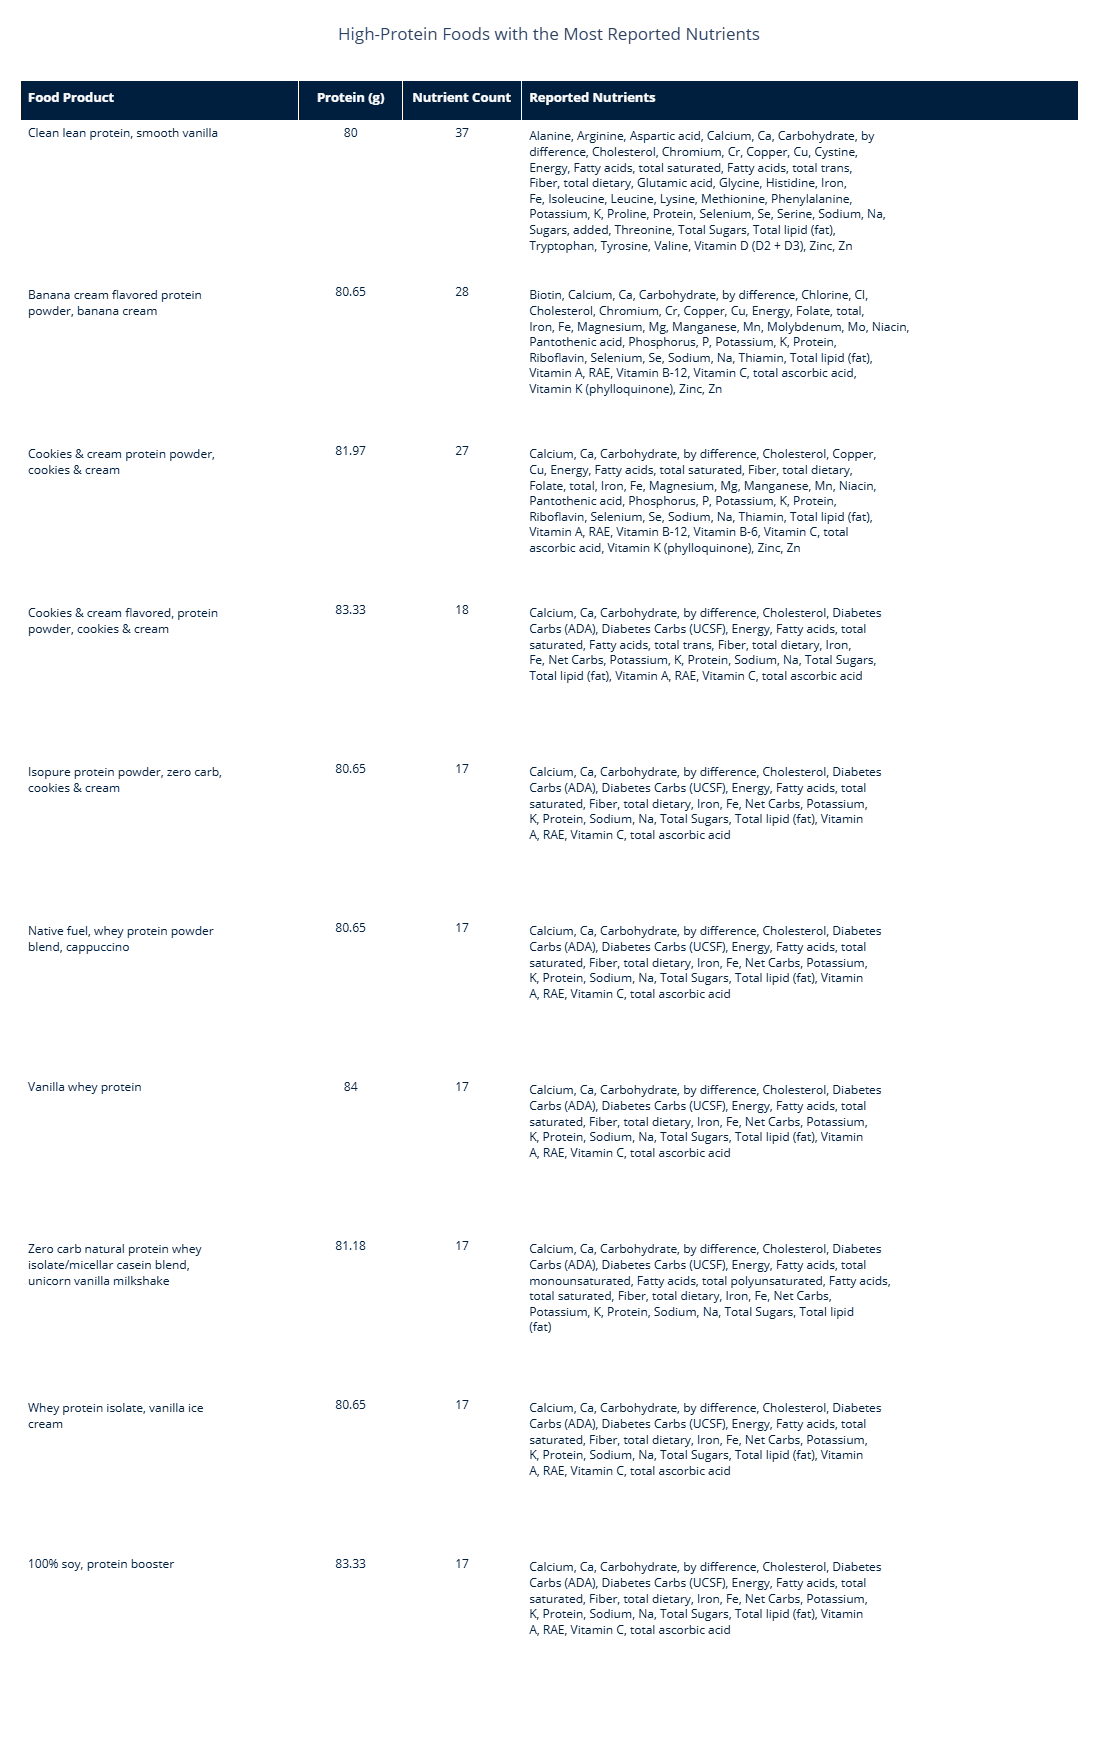

In [110]:
df = protein_reported_nutrients.head(10).copy()
df["protein_g"] = df["protein_g"].round(2)

def wrap_text(text, width=50):
    if pd.isna(text):
        return ""
    return "<br>".join(
        textwrap.wrap(str(text), width=width)
    )

# Wrapping food names and nutrient lists
df["food_name"] = df["food_name"].apply(
    lambda x: wrap_text(x, 35)
)

df["reported_nutrients"] = df["reported_nutrients"].apply(
    lambda x: wrap_text(x, 65)
)

df = df[
    ["food_name", "protein_g", "nutrient_count", "reported_nutrients"]
]

df.columns = [
    "Food Product",
    "Protein (g)",
    "Nutrient Count",
    "Reported Nutrients"
]

# Calculating the number of lines needed per row
def count_lines(text):
    return str(text).count("<br>") + 1

max_lines = max(
    max(count_lines(food), count_lines(nutrients))
    for food, nutrients in zip(
        df["Food Product"],
        df["Reported Nutrients"]
    )
)

# Set heights to accommodate wrapped text
row_height = max(40, max_lines * 18 + 15)
header_height = 40

fig_height = (
    len(df) * row_height
    + header_height
    + 100
)

# Create the table
fig = go.Figure(
    data=[
        go.Table(
            columnwidth=[200, 75, 85, 400],
            header=dict(
                values=[f"<b>{col}</b>" for col in df.columns],
                fill_color="#001F3F",
                font=dict(color="white", size=13),
                align=["left", "center", "center", "left"],
                height=header_height
            ),
            cells=dict(
                values=[df[col].tolist() for col in df.columns],
                fill_color="#FFFFFF",
                font=dict(color="#001F3F", size=12),
                align=["left", "center", "center", "left"],
                height=row_height
            )
        )
    ]
)

# Configure chart layout
fig.update_layout(
    title="High-Protein Foods with the Most Reported Nutrients",
    title_x=0.5,
    width=1400,
    height=fig_height,
    margin=dict(l=20, r=20, t=80, b=20)
)

fig.show()

## Conclusion

As we come to the end of the analysis, we realize that it is increasingly important to look beyond the protein content in foods. In this article, we learned to retrieve food and nutritional information from the Noms API, and ingest them in a GridDB Collections container using the Web API. We leveraged GridDB's SQL capabilities, including both standard and specialized functions like Self and Cross joins, nested subqueries and GROUP_CONCAT(). We used the Noms data to analyze protein density, compare sodium-to-protein and saturated-fat-to-protein ratios in food products. We then identified brands with higher average protein content and examined the variety of nutrients reported across food products. Overall, this demonstration illustrates how GridDB can be used to store, query, and analyze structured nutritional data, turning raw API responses into meaningful insights through SQL.